# GameTheory-02-NormalForm-Python

**Navigation** : [<< 1-Setup](GameTheory-01-Setup-Python.ipynb) | [Index](README.md) | [3-Topology2x2 >>](GameTheory-03-Topology2x2-Python.ipynb)

**Side tracks** : [2b-Lean-Definitions](GameTheory-02b-Lean-Definitions-Lean.ipynb) | [2d-Epistemique](GameTheory-02d-Epistemique-Connaissance-Commune-Python.ipynb)

## Jeux en Forme Normale

Ce notebook introduit la representation des jeux en **forme normale** (ou forme stratégique), la facon standard de decrire les interactions stratégiques.

### Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :
1. **Définir** formellement un jeu en forme normale (joueurs, stratégies, gains)
2. **Representer** un jeu par des matrices de gains et l'implementer en Python
3. **Identifier** les stratégies dominantes et dominees
4. **Calculer** les meilleures reponses (best response) d'un joueur
5. **Appliquer** l'elimination iteree des stratégies dominees (IESDS)
6. **Reconnaitre** les jeux classiques : Dilemme du Prisonnier, Stag Hunt, Chicken, etc.

### Concepts cles
- **Forme normale** : representation complete d'un jeu par ses matrices
- **Dominance** : une stratégie toujours meilleure qu'une autre
- **Best response** : stratégie optimale face a un choix adverse donne
- **IESDS** : simplification par elimination des stratégies irrationnelles

### Duree estimee : 45 minutes

### Prerequis
- Notebook 1 (Setup) complete
- Notions de base en algebre lineaire (matrices)


> *Ancres savantes -- von Neumann, J. (1928), Zur Théorie der Gesellschaftsspiele, Mathematische Annalen 100:295-320 (theoreme du minimax pour les jeux a somme nulle, déjà nomme ci-dessus — toute matrice de gains admet une valeur en stratégies mixtes) ; von Neumann, J. & Morgenstern, O. (1944), Theory of Games and Economic Behavior, Princeton University Press (acte de naissance de la théorie des jeux moderne : formalisme des jeux en forme normale G=(N,S,u) enseigne dans ce notebook, axiomes d'utilite esperee justifiant la maximisation du gain esperer) ; Nash, J.F. (1950), Equilibrium Points in N-Person Games, Proceedings of the National Academy of Sciences 36(1):48-49 (theoreme d'existence de l'equilibre de Nash, déjà nomme ci-dessus — tout jeu fini possede au moins un equilibre en stratégies mixtes) ; Nash, J.F. (1951), Non-Cooperative Games, Annals of Mathematics 54(2):286-295 (version journal, preuve via le theoreme du point fixe de Brouwer ; prix Nobel d'economie 1994).*

In [1]:
# Imports
import numpy as np
import nashpy as nash
import matplotlib.pyplot as plt
from typing import List, Tuple, Optional
import warnings
warnings.filterwarnings('ignore')
print("Imports OK : numpy, matplotlib, itertools")


Imports OK : numpy, matplotlib, itertools


## 1. Definition formelle

### Jeu en forme normale

Un jeu en forme normale est défini par un triplet $G = (N, S, u)$ :

- $N = \{1, 2, ..., n\}$ : ensemble des **joueurs**
- $S = S_1 \times S_2 \times ... \times S_n$ : espace des **stratégies**
  - $S_i$ : stratégies disponibles pour le joueur $i$
- $u = (u_1, u_2, ..., u_n)$ : fonctions d'**utilite** (gains)
  - $u_i : S \to \mathbb{R}$ : gain du joueur $i$ pour chaque profil de stratégies

**Source primaire.** La representation d'un jeu en forme normale (ou stratégique) par le triplet $G = (N, S, u)$ -- joueurs, stratégies, fonctions d'utilite -- est codifiee par John von Neumann et Oskar Morgenstern dans *Theory of Games and Economic Behavior* (Princeton University Press, 1944), l'ouvrage fondateur de la théorie des jeux. Ce cadre, qui systematise l'usage des matrices de gains et de l'utilite esperee, demeure la definition standard de reference ; les notions de meilleure reponse et d'equilibre etudiees plus loin dans cette serie s'appuient directement sur ce formalisme.

### Cas particulier : jeux 2 joueurs

Pour 2 joueurs avec $m$ et $n$ stratégies, on represente le jeu par deux matrices :
- $A \in \mathbb{R}^{m \times n}$ : gains du joueur Ligne (Row)
- $B \in \mathbb{R}^{m \times n}$ : gains du joueur Colonne (Column)

$A_{ij}$ = gain de Ligne quand Ligne joue $i$ et Colonne joue $j$

In [2]:
class NormalFormGame:
    """
    Representation d'un jeu en forme normale pour 2 joueurs.
    """
    
    def __init__(self, A: np.ndarray, B: np.ndarray, 
                 row_actions: List[str] = None,
                 col_actions: List[str] = None,
                 name: str = "Game"):
        """
        Args:
            A: Matrice des gains du joueur Ligne (m x n)
            B: Matrice des gains du joueur Colonne (m x n)
            row_actions: Noms des actions du joueur Ligne
            col_actions: Noms des actions du joueur Colonne
            name: Nom du jeu
        """
        self.A = np.array(A)
        self.B = np.array(B)
        self.name = name
        
        assert self.A.shape == self.B.shape, "Les matrices doivent avoir la meme forme"
        
        self.m, self.n = self.A.shape  # m actions Ligne, n actions Colonne
        
        self.row_actions = row_actions or [f"R{i}" for i in range(self.m)]
        self.col_actions = col_actions or [f"C{j}" for j in range(self.n)]
        
        # Creer le jeu Nashpy
        self.nash_game = nash.Game(self.A, self.B)
    
    def __repr__(self):
        return f"NormalFormGame('{self.name}', {self.m}x{self.n})"
    
    def payoff(self, i: int, j: int) -> Tuple[float, float]:
        """Retourne les gains pour le profil (i, j)."""
        return (self.A[i, j], self.B[i, j])
    
    def display(self):
        """Affiche le jeu sous forme de tableau."""
        print(f"\n{self.name}")
        print("=" * (len(self.name) + 10))
        
        # Header
        header = "          " + "  ".join(f"{c:>10}" for c in self.col_actions)
        print(header)
        print("-" * len(header))
        
        # Rows
        for i, row_action in enumerate(self.row_actions):
            row_str = f"{row_action:>8}  "
            for j in range(self.n):
                row_str += f"({self.A[i,j]:>3}, {self.B[i,j]:>3})  "
            print(row_str)

# Test
A = np.array([[3, 0], [5, 1]])
B = np.array([[3, 5], [0, 1]])
pd = NormalFormGame(A, B, ['Cooperer', 'Defaire'], ['Cooperer', 'Defaire'], 
                    name="Dilemme du Prisonnier")
pd.display()


Dilemme du Prisonnier
            Cooperer     Defaire
--------------------------------
Cooperer  (  3,   3)  (  0,   5)  
 Defaire  (  5,   0)  (  1,   1)  


### Interprétation - Premier exemple

La sortie affiche la **matrice de gains** du Dilemme du Prisonnier. Chaque cellule contient une paire `(gain Ligne, gain Colonne)`.

| Profil de stratégies | Gains | Interprétation |
|---------------------|-------|----------------|
| (Cooperer, Cooperer) | (3, 3) | Issue optimale collective |
| (Defaire, Defaire) | (1, 1) | Issue rationnelle individuelle |
| (Cooperer, Defaire) | (0, 5) | Trahison du joueur Colonne |
| (Defaire, Cooperer) | (5, 0) | Trahison du joueur Ligne |

**Observation** : L'issue (Cooperer, Cooperer) donne le meilleur gain total (6), mais chaque joueur a une **incitation à dévier** pour obtenir 5 au lieu de 3.

## 2. Jeux classiques 2x2

Explorons plusieurs jeux classiques pour comprendre les différentes structures possibles.

In [3]:
# Collection de jeux classiques

def create_prisoners_dilemma():
    """Dilemme du Prisonnier - Probleme de cooperation."""
    A = np.array([[3, 0], [5, 1]])
    B = np.array([[3, 5], [0, 1]])
    return NormalFormGame(A, B, ['Cooperer', 'Defaire'], ['Cooperer', 'Defaire'],
                          "Dilemme du Prisonnier")

def create_stag_hunt():
    """Chasse au Cerf - Probleme de coordination avec risque."""
    A = np.array([[4, 0], [3, 3]])
    B = np.array([[4, 3], [0, 3]])
    return NormalFormGame(A, B, ['Cerf', 'Lievre'], ['Cerf', 'Lievre'],
                          "Chasse au Cerf (Stag Hunt)")

def create_battle_of_sexes():
    """Bataille des Sexes - Probleme de coordination pure."""
    A = np.array([[3, 0], [0, 2]])
    B = np.array([[2, 0], [0, 3]])
    return NormalFormGame(A, B, ['Opera', 'Football'], ['Opera', 'Football'],
                          "Bataille des Sexes")

def create_chicken():
    """Jeu du Poulet - Anti-coordination."""
    A = np.array([[0, -1], [1, -10]])
    B = np.array([[0, 1], [-1, -10]])
    return NormalFormGame(A, B, ['Devier', 'Continuer'], ['Devier', 'Continuer'],
                          "Jeu du Poulet (Chicken)")

def create_matching_pennies():
    """Matching Pennies - Jeu a somme nulle."""
    A = np.array([[1, -1], [-1, 1]])
    B = np.array([[-1, 1], [1, -1]])
    return NormalFormGame(A, B, ['Pile', 'Face'], ['Pile', 'Face'],
                          "Matching Pennies")

# Afficher tous les jeux
games = [
    create_prisoners_dilemma(),
    create_stag_hunt(),
    create_battle_of_sexes(),
    create_chicken(),
    create_matching_pennies()
]

for game in games:
    game.display()


Dilemme du Prisonnier
            Cooperer     Defaire
--------------------------------
Cooperer  (  3,   3)  (  0,   5)  
 Defaire  (  5,   0)  (  1,   1)  

Chasse au Cerf (Stag Hunt)
                Cerf      Lievre
--------------------------------
    Cerf  (  4,   4)  (  0,   3)  
  Lievre  (  3,   0)  (  3,   3)  

Bataille des Sexes
               Opera    Football
--------------------------------
   Opera  (  3,   2)  (  0,   0)  
Football  (  0,   0)  (  2,   3)  

Jeu du Poulet (Chicken)
              Devier   Continuer
--------------------------------
  Devier  (  0,   0)  ( -1,   1)  
Continuer  (  1,  -1)  (-10, -10)  

Matching Pennies
                Pile        Face
--------------------------------
    Pile  (  1,  -1)  ( -1,   1)  
    Face  ( -1,   1)  (  1,  -1)  


### Interprétation - Jeux classiques

Les 5 jeux affichés illustrent différentes **structures d'interaction stratégique** :

| Jeu | Structure | Propriété clé |
|-----|-----------|---------------|
| Dilemme du Prisonnier | Conflit coopération/intérêt | Inefficience de l'équilibre |
| Chasse au Cerf | Coordination avec risque | Deux équilibres purs |
| Bataille des Sexes | Coordination pure | Conflit de préférence |
| Jeu du Poulet | Anti-coordination | Escalade dangereuse |
| Matching Pennies | Compétition pure | Jeu à somme nulle |

**Points remarquables** :
- Dans **Stag Hunt**, (Cerf, Cerf) donne 4 à chacun, mais (Lièvre, Lièvre) est plus sûr (gain garanti 3)
- Dans **Bataille des Sexes**, les deux joueurs préfèrent se coordonner (Opera ou Football) plutôt que se décoordiner
- Dans **Chicken**, le pire résultat (-10, -10) survient si les deux joueurs continuent

## 3. Dominance

### Definitions

Une stratégie $s_i$ **domine strictement** une stratégie $s_i'$ si :
$$u_i(s_i, s_{-i}) > u_i(s_i', s_{-i}) \quad \forall s_{-i} \in S_{-i}$$

Une stratégie $s_i$ **domine faiblement** une stratégie $s_i'$ si :
$$u_i(s_i, s_{-i}) \geq u_i(s_i', s_{-i}) \quad \forall s_{-i}$$
avec au moins une inegalite stricte.

Une stratégie est **dominante** si elle domine toutes les autres stratégies.

> **Note — alias rétrograde.** Le nom court `find_dominant_strategy` reste
> disponible comme alias de `find_weakly_dominant_strategy`. Son comportement
> a changé sur un cas dégénéré : face à des stratégies *interchangeables*
> (mêmes gains contre toute réponse adverse), l'ancienne implémentation
> reclassait la première rencontrée comme dominante ; l'alias renvoie
> désormais `None`. Une stratégie interchangeable n'est pas dominante, elle
> est équivalente à une autre. Si votre jeu comporte des stratégies
> interchangeables, lisez la sémantique ci-dessus comme faible et stricte.

In [4]:
def is_strictly_dominated(game: NormalFormGame, player: int, strategy: int) -> Tuple[bool, Optional[int]]:
    """
    Verifie si une strategie est strictement dominee.
    
    Args:
        game: Le jeu
        player: 0 pour Ligne, 1 pour Colonne
        strategy: Index de la strategie a verifier
    
    Returns:
        (is_dominated, dominating_strategy)
    """
    if player == 0:  # Joueur Ligne
        payoffs = game.A
        n_strategies = game.m
    else:  # Joueur Colonne
        payoffs = game.B.T  # Transposer pour traiter uniformement
        n_strategies = game.n
    
    for other in range(n_strategies):
        if other == strategy:
            continue
        
        # Verifier si 'other' domine strictement 'strategy'
        if player == 0:
            dominates = all(game.A[other, j] > game.A[strategy, j] for j in range(game.n))
        else:
            dominates = all(game.B[i, other] > game.B[i, strategy] for i in range(game.m))
        
        if dominates:
            return True, other
    
    return False, None

def find_weakly_dominant_strategy(game: NormalFormGame, player: int) -> Optional[int]:
    """
    Trouve une strategie FAIBLEMENT dominante pour un joueur.
    
    Strategie s faiblement dominante si elle est AU MOINS aussi bonne que toute
    autre strategie 'other' sur tous les profils d'adversaire, avec AU MOINS une
    inegalite stricte. La clause stricte evite qu'une strategie identique a une
    autre soit declaree "faiblement dominante" -- deux strategies strictement
    identiques ne se dominent faiblement l'une l'autre (elles sont interchangeables).
    
    Returns:
        Index de la strategie faiblement dominante, ou None si aucune.
    """
    n_strategies = game.m if player == 0 else game.n
    
    for s in range(n_strategies):
        is_dominant = True
        for other in range(n_strategies):
            if other == s:
                continue
            
            if player == 0:
                pays = [game.A[s, j] - game.A[other, j] for j in range(game.n)]
            else:
                pays = [game.B[i, s] - game.B[i, other] for i in range(game.m)]
            
            # Faible dominance = partout >= ET quelque part > (clause stricte)
            if not all(p >= 0 for p in pays) or not any(p > 0 for p in pays):
                is_dominant = False
                break
        
        if is_dominant:
            return s
    
    return None


def find_strictly_dominant_strategy(game: NormalFormGame, player: int) -> Optional[int]:
    """
    Trouve une strategie STRICTEMENT dominante pour un joueur.
    
    Strategie s strictement dominante si elle est strictement meilleure que toute
    autre strategie 'other' sur TOUS les profils d'adversaire. Cette fonction est
    le pendant direct de `is_strictly_dominated` (qui teste une strategie donnee) :
    elle cherche la strategie dominante plutot que de la verifier.
    
    Returns:
        Index de la strategie strictement dominante, ou None si aucune.
    """
    n_strategies = game.m if player == 0 else game.n
    
    for s in range(n_strategies):
        is_dominant = True
        for other in range(n_strategies):
            if other == s:
                continue
            
            if player == 0:
                dominates = all(game.A[s, j] > game.A[other, j] for j in range(game.n))
            else:
                dominates = all(game.B[i, s] > game.B[i, other] for i in range(game.m))
            
            if not dominates:
                is_dominant = False
                break
        
        if is_dominant:
            return s
    
    return None


# Alias retrograde -- conserve pour le materiel pedagogique anterieur, qui
# appelait le nom court `find_dominant_strategy`. La fonction explicite
# `find_weakly_dominant_strategy` porte la semantique faible corrigee.
# ATTENTION : sur des strategies interchangeables (memes gains contre toute
# reponse), l'ancienne version renvoyait l'index 0 ; l'alias, qui applique la
# semantique faible corrigee, renvoie None. C'est la correction portee par
# #21192 -- une strategie interchangeable n'est pas dominante.
find_dominant_strategy = find_weakly_dominant_strategy

# Analyser le Dilemme du Prisonnier
pd = create_prisoners_dilemma()
pd.display()

print("\nAnalyse de dominance:")
print("-" * 40)

# Joueur Ligne
dom_row = find_weakly_dominant_strategy(pd, 0)
if dom_row is not None:
    print(f"Joueur Ligne: '{pd.row_actions[dom_row]}' est faiblement dominante")
else:
    print("Joueur Ligne: pas de strategie faiblement dominante")

# Joueur Colonne
dom_col = find_weakly_dominant_strategy(pd, 1)
if dom_col is not None:
    print(f"Joueur Colonne: '{pd.col_actions[dom_col]}' est faiblement dominante")


Dilemme du Prisonnier
            Cooperer     Defaire
--------------------------------
Cooperer  (  3,   3)  (  0,   5)  
 Defaire  (  5,   0)  (  1,   1)  

Analyse de dominance:
----------------------------------------
Joueur Ligne: 'Defaire' est faiblement dominante
Joueur Colonne: 'Defaire' est faiblement dominante


### Exemple : Bataille des Sexes

Analysons maintenant un jeu de **coordination** où la meilleure réponse change selon l'action de l'adversaire.

In [5]:
# Analyser tous les jeux classiques
print("Analyse de dominance pour les jeux classiques")
print("=" * 50)

for game in games:
    print(f"\n{game.name}:")
    
    dom_row = find_weakly_dominant_strategy(game, 0)
    dom_col = find_weakly_dominant_strategy(game, 1)
    
    if dom_row is not None:
        print(f"  Ligne: '{game.row_actions[dom_row]}' est faiblement dominante")
    else:
        print(f"  Ligne: pas de strategie faiblement dominante")
    
    if dom_col is not None:
        print(f"  Colonne: '{game.col_actions[dom_col]}' est faiblement dominante")
    else:
        print(f"  Colonne: pas de strategie faiblement dominante")

Analyse de dominance pour les jeux classiques

Dilemme du Prisonnier:
  Ligne: 'Defaire' est faiblement dominante
  Colonne: 'Defaire' est faiblement dominante

Chasse au Cerf (Stag Hunt):
  Ligne: pas de strategie faiblement dominante
  Colonne: pas de strategie faiblement dominante

Bataille des Sexes:
  Ligne: pas de strategie faiblement dominante
  Colonne: pas de strategie faiblement dominante

Jeu du Poulet (Chicken):
  Ligne: pas de strategie faiblement dominante
  Colonne: pas de strategie faiblement dominante

Matching Pennies:
  Ligne: pas de strategie faiblement dominante
  Colonne: pas de strategie faiblement dominante


### Interprétation - Équilibres et stratégies dominantes

**Résultats remarquables** :

| Jeu | Nombre d'équilibres purs | Caractéristique |
|-----|-------------------------|-----------------|
| Dilemme du Prisonnier | 1 | Unique, inefficient (gain 1 vs optimal 3) |
| Stag Hunt | 2 | Risque de coordination (Cerf meilleur mais risqué) |
| Bataille des Sexes | 2 | Conflit de préférence (3,2 vs 2,3) |
| Chicken | 2 | Asymétriques (un joueur cède) |
| Matching Pennies | 0 | Nécessite stratégies mixtes |

**Points clés** :
- **Stag Hunt** : L'équilibre (Cerf, Cerf) Pareto-domine (Lièvre, Lièvre), mais est plus risqué
- **Chicken** : Les deux équilibres sont asymétriques → un joueur doit céder, mais lequel ?
- **Matching Pennies** : Aucun équilibre pur → les joueurs doivent **randomiser**

**Résultat clé** : Seul le Dilemme du Prisonnier possède une stratégie dominante pour les deux joueurs.

| Jeu | Stratégie dominante Ligne | Stratégie dominante Colonne | Conséquence |
|-----|---------------------------|----------------------------|-------------|
| Dilemme du Prisonnier | Defaire | Defaire | Issue unique et prévisible |
| Stag Hunt | Aucune | Aucune | Coordination nécessaire |
| Bataille des Sexes | Aucune | Aucune | Conflit de préférence |
| Chicken | Aucune | Aucune | Stratégie dépend de l'autre |
| Matching Pennies | Aucune | Aucune | Randomisation nécessaire |

**Implications** :
- Dans le **Dilemme du Prisonnier**, un joueur rationnel doit toujours jouer "Defaire", indépendamment de ce que fait l'adversaire
- Dans les autres jeux, le choix optimal **dépend** de la stratégie de l'adversaire → besoin du concept de **meilleure réponse**

### Observation

Seul le **Dilemme du Prisonnier** a une stratégie dominante pour les deux joueurs ("Defaire").

Les autres jeux necessitent des concepts plus raffines pour predire le comportement.

## 4. Meilleure Reponse (Best Response)

### Definition

La **meilleure reponse** du joueur $i$ a la stratégie $s_{-i}$ des autres joueurs est :
$$BR_i(s_{-i}) = \arg\max_{s_i \in S_i} u_i(s_i, s_{-i})$$

Pour les jeux 2x2 :
- $BR_{Ligne}(j)$ = stratégie de Ligne maximisant son gain quand Colonne joue $j$
- $BR_{Col}(i)$ = stratégie de Colonne maximisant son gain quand Ligne joue $i$

In [6]:
def best_response_row(game: NormalFormGame, col_strategy: int) -> List[int]:
    """
    Meilleure(s) reponse(s) du joueur Ligne a la strategie de Colonne.
    
    Returns:
        Liste des indices des meilleures reponses.
    """
    payoffs = game.A[:, col_strategy]
    max_payoff = np.max(payoffs)
    return [i for i in range(game.m) if payoffs[i] == max_payoff]

def best_response_col(game: NormalFormGame, row_strategy: int) -> List[int]:
    """
    Meilleure(s) reponse(s) du joueur Colonne a la strategie de Ligne.
    """
    payoffs = game.B[row_strategy, :]
    max_payoff = np.max(payoffs)
    return [j for j in range(game.n) if payoffs[j] == max_payoff]

def analyze_best_responses(game: NormalFormGame):
    """
    Analyse complete des meilleures reponses.
    """
    print(f"\nMeilleures reponses - {game.name}")
    print("=" * 50)
    
    print("\nJoueur Ligne (reponses aux actions de Colonne):")
    for j in range(game.n):
        br = best_response_row(game, j)
        br_names = [game.row_actions[i] for i in br]
        print(f"  Si Colonne joue '{game.col_actions[j]}' -> BR = {br_names}")
    
    print("\nJoueur Colonne (reponses aux actions de Ligne):")
    for i in range(game.m):
        br = best_response_col(game, i)
        br_names = [game.col_actions[j] for j in br]
        print(f"  Si Ligne joue '{game.row_actions[i]}' -> BR = {br_names}")

# Analyser le Dilemme du Prisonnier
pd = create_prisoners_dilemma()
analyze_best_responses(pd)


Meilleures reponses - Dilemme du Prisonnier

Joueur Ligne (reponses aux actions de Colonne):
  Si Colonne joue 'Cooperer' -> BR = ['Defaire']
  Si Colonne joue 'Defaire' -> BR = ['Defaire']

Joueur Colonne (reponses aux actions de Ligne):
  Si Ligne joue 'Cooperer' -> BR = ['Defaire']
  Si Ligne joue 'Defaire' -> BR = ['Defaire']


### Meilleures réponses : exemple de la Bataille des Sexes

Appliquons l'analyse de meilleures réponses à un jeu de **coordination** où la meilleure réponse change selon l'action adverse : la Bataille des Sexes. (L'équilibre en **stratégies mixtes** de Pierre-Feuille-Ciseaux, jeu sans équilibre pur, sera calculé avec Nashpy à la section 7.)

In [7]:
# Analyser la Bataille des Sexes
bos = create_battle_of_sexes()
bos.display()
analyze_best_responses(bos)


Bataille des Sexes
               Opera    Football
--------------------------------
   Opera  (  3,   2)  (  0,   0)  
Football  (  0,   0)  (  2,   3)  

Meilleures reponses - Bataille des Sexes

Joueur Ligne (reponses aux actions de Colonne):
  Si Colonne joue 'Opera' -> BR = ['Opera']
  Si Colonne joue 'Football' -> BR = ['Football']

Joueur Colonne (reponses aux actions de Ligne):
  Si Ligne joue 'Opera' -> BR = ['Opera']
  Si Ligne joue 'Football' -> BR = ['Football']


### Relation avec l'equilibre de Nash

Un profil de stratégies $(s_i^*, s_{-i}^*)$ est un **equilibre de Nash** si et seulement si :
$$s_i^* \in BR_i(s_{-i}^*) \quad \forall i \in N$$

Autrement dit, chaque joueur joue une meilleure reponse a ce que jouent les autres.

### Interprétation - Coordination parfaite

**Observation** : Dans la Bataille des Sexes, les meilleures réponses sont **alignées** :

| Action Colonne | BR Ligne | Action Ligne | BR Colonne | Profil |
|----------------|----------|--------------|------------|--------|
| Opera | Opera | Opera | Opera | **(Opera, Opera)** ✓ |
| Football | Football | Football | Football | **(Football, Football)** ✓ |

**Structure de coordination** :
- Si Colonne joue "Opera", Ligne préfère aussi "Opera" (gain 3 > 0)
- Si Colonne joue "Football", Ligne préfère aussi "Football" (gain 2 > 0)
- Les deux profils où les joueurs se **coordonnent** sont des équilibres de Nash

> **Remarque** : Le problème n'est pas de trouver un équilibre, mais de **choisir lequel** ! (Ligne préfère Opera, Colonne préfère Football)

In [8]:
def find_pure_nash_equilibria(game: NormalFormGame) -> List[Tuple[int, int]]:
    """
    Trouve tous les equilibres de Nash en strategies pures.
    
    Un profil (i, j) est un Nash si:
    - i est meilleure reponse a j pour Ligne
    - j est meilleure reponse a i pour Colonne
    """
    equilibria = []
    
    for i in range(game.m):
        for j in range(game.n):
            # i est-il meilleure reponse a j ?
            br_row = best_response_row(game, j)
            # j est-il meilleure reponse a i ?
            br_col = best_response_col(game, i)
            
            if i in br_row and j in br_col:
                equilibria.append((i, j))
    
    return equilibria

# Trouver les equilibres Nash pour tous les jeux
print("Equilibres de Nash en strategies pures")
print("=" * 50)

for game in games:
    eq = find_pure_nash_equilibria(game)
    print(f"\n{game.name}:")
    
    if eq:
        for (i, j) in eq:
            # int() explicite : numpy 2 rend les scalaires sous la forme np.int64(1)
            # dans les f-strings, ce qui abime la lecture pedagogique des gains.
            payoff = tuple(int(v) for v in game.payoff(i, j))
            print(f"  ({game.row_actions[i]}, {game.col_actions[j]}) -> gains {payoff}")
    else:
        print("  Aucun equilibre en strategies pures")

Equilibres de Nash en strategies pures

Dilemme du Prisonnier:
  (Defaire, Defaire) -> gains (1, 1)

Chasse au Cerf (Stag Hunt):
  (Cerf, Cerf) -> gains (4, 4)
  (Lievre, Lievre) -> gains (3, 3)

Bataille des Sexes:
  (Opera, Opera) -> gains (3, 2)
  (Football, Football) -> gains (2, 3)

Jeu du Poulet (Chicken):
  (Devier, Continuer) -> gains (-1, 1)
  (Continuer, Devier) -> gains (1, -1)

Matching Pennies:
  Aucun equilibre en strategies pures


### Interprétation — ce que révèle le NOMBRE d'équilibres (1, 2, 2, 2, 0)

Le dump ci-dessus énumère les équilibres de Nash *purs* de cinq jeux canoniques. La quantité qui saute aux yeux n'est pas tel ou tel profil, mais le **nombre** d'équilibres par jeu — et ce nombre est une véritable **taxonomie** des jeux sous forme normale.

**1 équilibre — Dilemme du Prisonnier** : seul profil stable, `(Défaire, Défaire)` au gain `(1, 1)`. C'est précisément le drame : cet équilibre unique est **Pareto-dominé** — `(Coopérer, Coopérer)` donnerait mieux aux deux joueurs — mais `Défaire` *domine strictement* `Coopérer`, donc la rationalité individuelle verrouille les deux joueurs sur le pire issu collectif. Leçon : **un seul équilibre n'est pas synonyme de bon équilibre**. C'est le paradigme de l'échec de coordination par intérêt individuel.

**2 équilibres — Stag Hunt, Bataille des Sexes, Poulet** : ces trois jeux partagent une structure commune (deux profils auto-renforçants), mais la *nature* de la coordination diffère :

| Jeu | Deux équilibres | Tension |
|-----|-----------------|---------|
| Stag Hunt | `(Cerf,Cerf)` (4,4) vs `(Lièvre,Lièvre)` (3,3) | **Payoff-dominant** (4,4) vs **risk-dominant** (3,3 garanti même en cas de déviation de l'autre) |
| Bataille des Sexes | `(Opera,Opera)` (3,2) vs `(Football,Football)` (2,3) | Les deux eq sont Pareto-comparables, mais **chaque joueur préfère un eq différent** → conflit de sélection |
| Poulet (Chicken) | `(Dévier,Continuer)` (-1,1) vs `(Continuer,Devier)` (1,-1) | Eq **asymétriques** : chacun veut que l'autre cède ; le pire `(Continuer,Continuer)` n'est PAS un eq → incitation à la *brinkmanship* |

→ Pour ces jeux, le problème n'est plus de *trouver* un équilibre (ils existent), mais de le **choisir** : c'est le problème de la *sélection d'équilibre*, qui exigera des concepts complémentaires (focal points, évolution, communication).

**0 équilibre — Matching Pennies** : aucune stratégie pure n'est stable, car les meilleures réponses **cyclent** (si Ligne joue Pile, Colonne répond **Face** — elle gagne à dématcher ; Ligne suit alors sur **Face** — il gagne à matcher ; Colonne bascule sur **Pile** ; etc.) sans point fixe. C'est précisément ce qui **force à sortir du cadre déterministe** : sans stratégie pure stable, la seule issue est la **randomisation**.

La grille `1 / 2 / 2 / 2 / 0` n'est donc pas anecdotique : elle prédit la pathologie du jeu (dilemme social / sélection / instabilité) et dicte l'outil approprié (pur / coordination / mixte). Les sections suivantes explorent ces trois issues — la visualisation (§5) pour *voir* les meilleures réponses s'aligner, IESDS (§6) pour simplifier un jeu par élimination, puis **Pierre-Feuille-Ciseaux (§7)** qui retrouvera la structure cyclique du *0 équilibre*, résolue dans la même section par les **stratégies mixtes**.

## 5. Visualisation des meilleures reponses

Visualisons les meilleures reponses dans la matrice de gains.

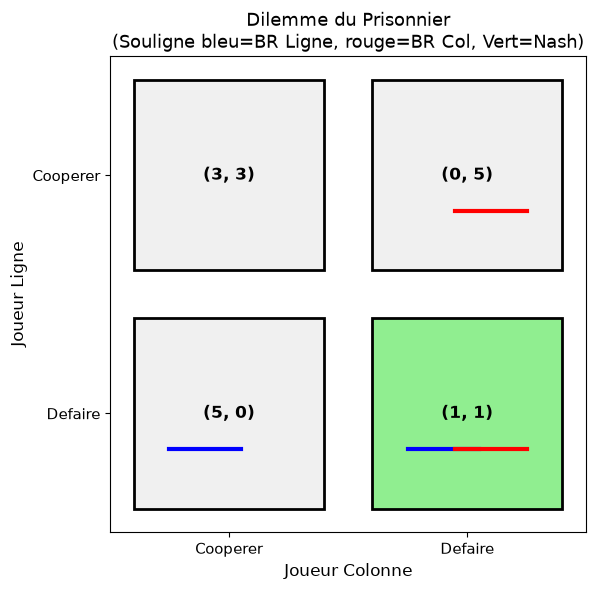

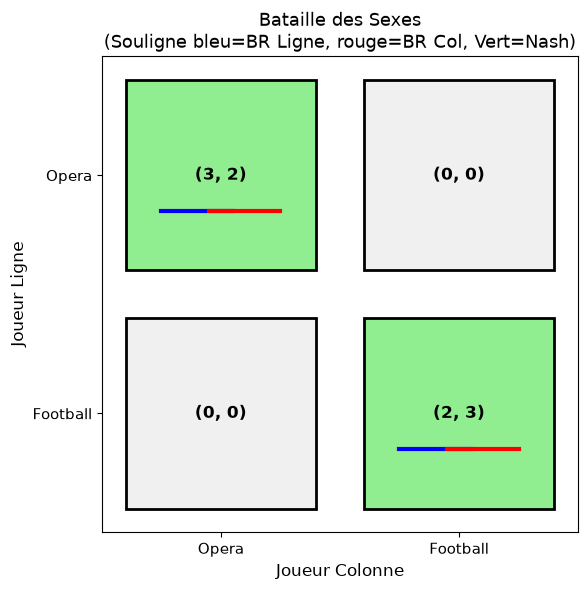

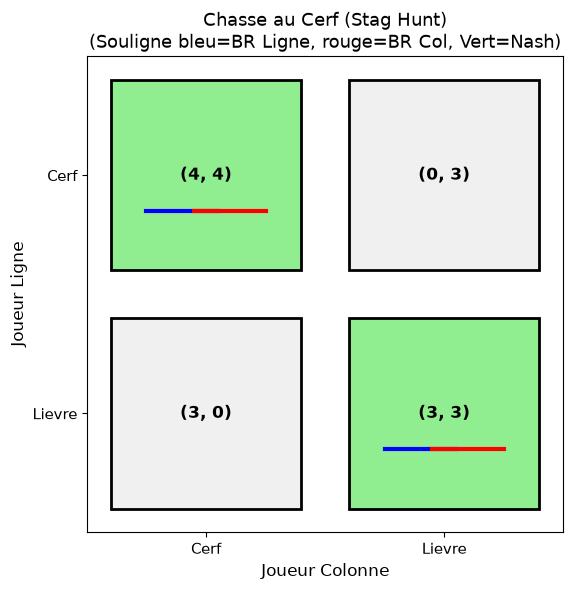

In [9]:
def plot_game_with_br(game: NormalFormGame):
    """
    Visualise un jeu avec les meilleures reponses marquees.
    
    - Cercle autour du gain de Ligne si meilleure reponse
    - Carre autour du gain de Colonne si meilleure reponse
    - Fond vert si equilibre de Nash
    """
    fig, ax = plt.subplots(figsize=(8, 6))
    
    # Trouver les meilleures reponses
    br_row_map = {j: best_response_row(game, j) for j in range(game.n)}
    br_col_map = {i: best_response_col(game, i) for i in range(game.m)}
    
    # Equilibres Nash
    nash_eq = find_pure_nash_equilibria(game)
    
    for i in range(game.m):
        for j in range(game.n):
            # Position de la cellule
            x, y = j, game.m - 1 - i
            
            # Couleur de fond
            if (i, j) in nash_eq:
                color = '#90EE90'  # Vert clair pour Nash
            else:
                color = '#F0F0F0'  # Gris clair
            
            rect = plt.Rectangle((x-0.4, y-0.4), 0.8, 0.8,
                                   facecolor=color, edgecolor='black', linewidth=2)
            ax.add_patch(rect)
            
            # Gains
            payoff_text = f"({game.A[i,j]}, {game.B[i,j]})"
            ax.text(x, y, payoff_text, ha='center', va='center', 
                   fontsize=12, fontweight='bold')
            
            # Marquer meilleure reponse Ligne (souligner le premier nombre)
            if i in br_row_map[j]:
                ax.plot([x-0.25, x+0.05], [y-0.15, y-0.15], 'b-', linewidth=3)
            
            # Marquer meilleure reponse Colonne (souligner le second nombre)
            if j in br_col_map[i]:
                ax.plot([x-0.05, x+0.25], [y-0.15, y-0.15], 'r-', linewidth=3)
    
    # Configuration des axes
    ax.set_xlim(-0.5, game.n - 0.5)
    ax.set_ylim(-0.5, game.m - 0.5)
    
    ax.set_xticks(range(game.n))
    ax.set_yticks(range(game.m))
    ax.set_xticklabels(game.col_actions, fontsize=11)
    ax.set_yticklabels(game.row_actions[::-1], fontsize=11)
    
    ax.set_xlabel('Joueur Colonne', fontsize=12)
    ax.set_ylabel('Joueur Ligne', fontsize=12)
    ax.set_title(f"{game.name}\n(Souligne bleu=BR Ligne, rouge=BR Col, Vert=Nash)", 
                fontsize=13)
    
    ax.set_aspect('equal')
    plt.tight_layout()
    plt.show()

# Visualiser plusieurs jeux
plot_game_with_br(create_prisoners_dilemma())
plot_game_with_br(create_battle_of_sexes())
plot_game_with_br(create_stag_hunt())

### Interprétation - Visualisations

Les graphiques montrent les **meilleures réponses** et **équilibres de Nash** :

**Légende** :
- **Soulignement bleu** sous le premier nombre : Ligne joue une meilleure réponse
- **Soulignement rouge** sous le second nombre : Colonne joue une meilleure réponse
- **Fond vert** : Équilibre de Nash (les deux joueurs jouent une BR)

**Observations** :
1. **Dilemme du Prisonnier** : (Defaire, Defaire) a les deux soulignements → unique Nash
2. **Bataille des Sexes** : Deux cellules vertes (Opera, Opera) et (Football, Football)
3. **Stag Hunt** : Deux équilibres, mais (Cerf, Cerf) donne des gains supérieurs

## 6. Elimination iteree des stratégies dominees (IESDS)

L'**Iterated Elimination of Strictly Dominated Stratégies** permet de simplifier un jeu en eliminant successivement les stratégies qu'aucun joueur rationnel ne jouerait.

In [10]:
def eliminate_dominated_strategies(A: np.ndarray, B: np.ndarray, 
                                    row_names: List[str], col_names: List[str],
                                    verbose: bool = True) -> Tuple[np.ndarray, np.ndarray, List[str], List[str]]:
    """
    Elimination iteree des strategies strictement dominees.
    
    Returns:
        Matrices et noms reduits.
    """
    A = A.copy()
    B = B.copy()
    row_names = list(row_names)
    col_names = list(col_names)
    
    iteration = 0
    changed = True
    
    while changed:
        changed = False
        iteration += 1
        
        # Eliminer strategies dominees pour Ligne
        m = A.shape[0]
        to_remove = []
        
        for i in range(m):
            for other in range(m):
                if other == i or other in to_remove:
                    continue
                # 'other' domine strictement 'i' ?
                if all(A[other, j] > A[i, j] for j in range(A.shape[1])):
                    to_remove.append(i)
                    if verbose:
                        print(f"Iteration {iteration}: Ligne '{row_names[i]}' dominee par '{row_names[other]}'")
                    break
        
        if to_remove:
            changed = True
            keep = [i for i in range(m) if i not in to_remove]
            A = A[keep, :]
            B = B[keep, :]
            row_names = [row_names[i] for i in keep]
        
        # Eliminer strategies dominees pour Colonne
        n = A.shape[1]
        to_remove = []
        
        for j in range(n):
            for other in range(n):
                if other == j or other in to_remove:
                    continue
                # 'other' domine strictement 'j' ?
                if all(B[i, other] > B[i, j] for i in range(A.shape[0])):
                    to_remove.append(j)
                    if verbose:
                        print(f"Iteration {iteration}: Colonne '{col_names[j]}' dominee par '{col_names[other]}'")
                    break
        
        if to_remove:
            changed = True
            keep = [j for j in range(n) if j not in to_remove]
            A = A[:, keep]
            B = B[:, keep]
            col_names = [col_names[j] for j in keep]
    
    return A, B, row_names, col_names

# Exemple avec un jeu 3x3
print("Exemple d'IESDS sur un jeu 3x3")
print("=" * 50)

A = np.array([
    [4, 3, 2],
    [5, 4, 3],  # Domine la premiere ligne
    [3, 2, 1]
])
B = np.array([
    [1, 2, 1],
    [2, 3, 2],  # La colonne du milieu domine les autres
    [1, 2, 1]
])

game_3x3 = NormalFormGame(A, B, ['R1', 'R2', 'R3'], ['C1', 'C2', 'C3'], "Jeu 3x3")
game_3x3.display()

print("\nElimination iteree:")
print("-" * 40)
A_red, B_red, row_red, col_red = eliminate_dominated_strategies(
    A, B, ['R1', 'R2', 'R3'], ['C1', 'C2', 'C3'])

print(f"\nJeu reduit: {len(row_red)}x{len(col_red)}")
print(f"Strategies restantes: Ligne={row_red}, Colonne={col_red}")

# Garantie : l'IESDS STRICTE ne predit un equilibre de Nash que si le jeu
# reduit est de taille 1x1. Sinon, plusieurs issues coexistent et leur
# statut d'equilibre doit etre verifie par find_pure_nash_equilibria.
if len(row_red) == 1 and len(col_red) == 1:
    print(f"Issue predite (IESDS) : ({row_red[0]}, {col_red[0]}) avec gains ({A_red[0,0]}, {B_red[0,0]})")
else:
    red_game = NormalFormGame(A_red, B_red, row_red, col_red, "Jeu reduit IESDS")
    candidates = find_pure_nash_equilibria(red_game)
    print(f"Jeu reduit non trivial ({len(row_red)}x{len(col_red)}), IESDS strict ne suffit pas : {len(candidates)} issue(s) candidate(s)")
    for (i, j) in candidates:
        print(f"  candidate IESDS : ({row_red[i]}, {col_red[j]}) avec gains ({A_red[i, j]}, {B_red[i, j]}) -- a verifier comme equilibre de Nash")


Exemple d'IESDS sur un jeu 3x3

Jeu 3x3
                  C1          C2          C3
--------------------------------------------
      R1  (  4,   1)  (  3,   2)  (  2,   1)  
      R2  (  5,   2)  (  4,   3)  (  3,   2)  
      R3  (  3,   1)  (  2,   2)  (  1,   1)  

Elimination iteree:
----------------------------------------
Iteration 1: Ligne 'R1' dominee par 'R2'
Iteration 1: Ligne 'R3' dominee par 'R2'
Iteration 1: Colonne 'C1' dominee par 'C2'
Iteration 1: Colonne 'C3' dominee par 'C2'

Jeu reduit: 1x1
Strategies restantes: Ligne=['R2'], Colonne=['C2']
Issue predite (IESDS) : (R2, C2) avec gains (4, 3)


### Interprétation - Simplification par IESDS

**Résultat** : Le processus d'IESDS a réduit le jeu 3×3 en un jeu **1×1** avec une issue unique.

**Étapes d'élimination** :
1. **R1 et R3** dominées par R2 (pour toutes les colonnes, R2 donne des gains supérieurs à Ligne)
2. **C1 et C3** dominées par C2 (pour la ligne restante R2, C2 donne des gains supérieurs à Colonne)

**Issue finale** : (R2, C2) avec gains (4, 3)

| Jeu | Taille initiale | Taille réduite | Issue prédite |
|-----|----------------|----------------|---------------|
| Exemple 3×3 | 3×3 (9 profils) | 1×1 (1 profil) | (R2, C2) = (4, 3) |

> **Propriété importante** : L'ordre d'élimination des stratégies strictement dominées n'affecte pas le résultat final (IESDS est **ordre-indépendant**)

## 7. Jeux a plus de 2 actions : Pierre-Feuille-Ciseaux

Le jeu **Pierre-Feuille-Ciseaux** (Rock-Paper-Scissors) est un jeu a somme nulle classique.

In [11]:
# Pierre-Feuille-Ciseaux
# Pierre bat Ciseaux, Ciseaux bat Feuille, Feuille bat Pierre

A_rps = np.array([
    [0, -1, 1],   # Pierre: nul vs P, perd vs F, gagne vs C
    [1, 0, -1],   # Feuille: gagne vs P, nul vs F, perd vs C
    [-1, 1, 0]    # Ciseaux: perd vs P, gagne vs F, nul vs C
])

B_rps = -A_rps  # Jeu a somme nulle

rps = NormalFormGame(A_rps, B_rps, 
                     ['Pierre', 'Feuille', 'Ciseaux'],
                     ['Pierre', 'Feuille', 'Ciseaux'],
                     "Pierre-Feuille-Ciseaux")
rps.display()

# Equilibres purs ?
eq = find_pure_nash_equilibria(rps)
print(f"\nEquilibres de Nash purs: {eq if eq else 'Aucun'}")

# Meilleures reponses
analyze_best_responses(rps)


Pierre-Feuille-Ciseaux
              Pierre     Feuille     Ciseaux
--------------------------------------------
  Pierre  (  0,   0)  ( -1,   1)  (  1,  -1)  
 Feuille  (  1,  -1)  (  0,   0)  ( -1,   1)  
 Ciseaux  ( -1,   1)  (  1,  -1)  (  0,   0)  

Equilibres de Nash purs: Aucun

Meilleures reponses - Pierre-Feuille-Ciseaux

Joueur Ligne (reponses aux actions de Colonne):
  Si Colonne joue 'Pierre' -> BR = ['Feuille']
  Si Colonne joue 'Feuille' -> BR = ['Ciseaux']
  Si Colonne joue 'Ciseaux' -> BR = ['Pierre']

Joueur Colonne (reponses aux actions de Ligne):
  Si Ligne joue 'Pierre' -> BR = ['Feuille']
  Si Ligne joue 'Feuille' -> BR = ['Ciseaux']
  Si Ligne joue 'Ciseaux' -> BR = ['Pierre']


### Interpretation - Structure cyclique de RPS

**Résultat** : Pierre-Feuille-Ciseaux n'a **aucun equilibre de Nash en stratégies pures**.

**Analyse des meilleures reponses** :

| Si l'adversaire joue | La meilleure reponse est |
|---------------------|-------------------------|
| Pierre | Feuille (bat Pierre) |
| Feuille | Ciseaux (bat Feuille) |
| Ciseaux | Pierre (bat Ciseaux) |

**Structure cyclique** : Les meilleures reponses forment un cycle :
$$\text{Pierre} \xrightarrow{BR} \text{Feuille} \xrightarrow{BR} \text{Ciseaux} \xrightarrow{BR} \text{Pierre}$$

**Pourquoi aucun equilibre pur ?**
- Pour tout profil de stratégies pures $(s_L, s_C)$, au moins un joueur veut devier
- Exemple : Si les deux jouent Pierre, chacun prefere jouer Feuille (gain +1 au lieu de 0)
- La structure cyclique garantit qu'il existe toujours une deviation profitable

> **Consequence** : L'equilibre doit etre en stratégies **mixtes** (randomisation)

In [12]:
# Equilibres mixtes avec Nashpy
print("\nEquilibres de Nash (purs et mixtes):")
print("-" * 40)

for eq in rps.nash_game.support_enumeration():
    sigma_row, sigma_col = eq
    print(f"\nJoueur Ligne:   {np.round(sigma_row, 3)}")
    print(f"Joueur Colonne: {np.round(sigma_col, 3)}")
    
    # Verifier si mixte
    if np.sum(sigma_row > 0.01) > 1:  # Plus d'une strategie jouee
        print("-> Equilibre en strategies mixtes")
        # Gain espere (devrait etre 0 dans un jeu symetrique a somme nulle)
        exp_payoff = sigma_row @ A_rps @ sigma_col
        print(f"   Gain espere: {exp_payoff:.3f}")


Equilibres de Nash (purs et mixtes):
----------------------------------------

Joueur Ligne:   [0.333 0.333 0.333]
Joueur Colonne: [0.333 0.333 0.333]
-> Equilibre en strategies mixtes
   Gain espere: 0.000


### Interpretation - Pierre-Feuille-Ciseaux

**Résultat cle** : L'unique equilibre de Nash de RPS est en stratégies **mixtes** avec probabilites uniformes (1/3, 1/3, 1/3).

**Structure cyclique des meilleures reponses** :

| Action Colonne | BR Ligne | Action Ligne | BR Colonne |
|----------------|----------|--------------|------------|
| Pierre | Feuille | Pierre | Feuille |
| Feuille | Ciseaux | Feuille | Ciseaux |
| Ciseaux | Pierre | Ciseaux | Pierre |

**Observations** :
- Les meilleures reponses forment un **cycle** : Pierre -> Feuille -> Ciseaux -> Pierre
- Aucun profil de stratégies pures n'est stable (chaque joueur veut toujours devier)
- L'equilibre mixte uniforme est la seule configuration stable

**Proprietes de l'equilibre mixte** :

| Propriete | Valeur | Signification |
|-----------|--------|---------------|
| Support | {Pierre, Feuille, Ciseaux} | Toutes les actions jouees |
| Probabilites | (1/3, 1/3, 1/3) | Distribution uniforme |
| Gain espere | 0.000 | Jeu equitable (somme nulle symetrique) |

**Intuition** :
- Si un joueur **favorise** une action (ex: jouer Pierre avec probabilite > 1/3), l'adversaire peut l'**exploiter** en augmentant sa probabilite de jouer Feuille
- Le seul equilibre est de jouer chaque action avec la même probabilite, rendant le comportement **imprevisible**
- Dans tout jeu a somme nulle **symetrique**, l'equilibre mixte donne un gain espere de 0 a chaque joueur

> **Theoreme de minimax (von Neumann, 1928)** : Dans un jeu a somme nulle, la valeur du jeu est unique et peut etre atteinte par des stratégies mixtes optimales.
> **Théorème (Nash, 1950)** : tout jeu fini possède au moins un équilibre de Nash (pur ou mixte).


In [13]:
# Verification : equilibres purs ET mixtes des jeux classiques + RPS
# (ancre le tableau du resume qui suit -- chaque compte y est imprime ici)
print("Equilibres de Nash (purs et mixtes) des jeux classiques")
print("=" * 55)

for game in games + [rps]:
    purs = find_pure_nash_equilibria(game)
    tous = list(game.nash_game.support_enumeration())
    mixtes = [(s_row, s_col) for s_row, s_col in tous
              if np.sum(s_row > 0.01) > 1 or np.sum(s_col > 0.01) > 1]
    print(f"\n{game.name}:")
    print(f"  {len(purs)} pur(s) + {len(mixtes)} mixte(s) "
          f"(total enumeration : {len(tous)})")
    for s_row, s_col in mixtes:
        print(f"  mixte : Ligne {np.round(s_row, 3)} / Colonne {np.round(s_col, 3)}")

Equilibres de Nash (purs et mixtes) des jeux classiques

Dilemme du Prisonnier:
  1 pur(s) + 0 mixte(s) (total enumeration : 1)

Chasse au Cerf (Stag Hunt):
  2 pur(s) + 1 mixte(s) (total enumeration : 3)
  mixte : Ligne [0.75 0.25] / Colonne [0.75 0.25]

Bataille des Sexes:
  2 pur(s) + 1 mixte(s) (total enumeration : 3)
  mixte : Ligne [0.6 0.4] / Colonne [0.4 0.6]

Jeu du Poulet (Chicken):
  2 pur(s) + 1 mixte(s) (total enumeration : 3)
  mixte : Ligne [0.9 0.1] / Colonne [0.9 0.1]

Matching Pennies:
  0 pur(s) + 1 mixte(s) (total enumeration : 1)
  mixte : Ligne [0.5 0.5] / Colonne [0.5 0.5]

Pierre-Feuille-Ciseaux:
  0 pur(s) + 1 mixte(s) (total enumeration : 1)
  mixte : Ligne [0.333 0.333 0.333] / Colonne [0.333 0.333 0.333]


## 8. Resume

### Concepts cles

| Concept | Definition |
|---------|------------|
| **Forme normale** | Representation par matrices de gains |
| **Stratégie dominante** | Toujours optimale, independamment des autres |
| **Stratégie dominee** | Jamais optimale, toujours battue |
| **Meilleure reponse** | Stratégie optimale etant donne les choix des autres |
| **Equilibre de Nash** | Profil ou chacun joue une meilleure reponse |
| **IESDS** | Simplification par elimination des stratégies irrationnelles |

### Types de jeux rencontres

| Jeu | Caractéristique | Equilibres Nash |
|----|-----------------|------------------|
| Dilemme du Prisonnier | Stratégie dominante | 1 pur (Defaire, Defaire) |
| Stag Hunt | Coordination avec risque | 2 purs + 1 mixte |
| Bataille des Sexes | Coordination pure | 2 purs + 1 mixte |
| Chicken | Anti-coordination | 2 purs + 1 mixte |
| Matching Pennies | Somme nulle | 1 mixte |
| RPS | Somme nulle symetrique | 1 mixte |

## 9. Exercices

Quatre exercices pour mettre en pratique les outils du notebook (`NormalFormGame`, `find_dominant_strategy`, `find_pure_nash_equilibria`, `best_response_*`, `support_enumeration`). Les solutions ne sont pas fournies : chaque cellule de code est un squelette a completer (`# TODO`).

### Exercice 1 : Variante du Dilemme du Prisonnier (3 actions)

Analysez une variante du Dilemme du Prisonnier avec 3 actions (Cooperer, Defaire, Punir) :

| | Cooperer | Defaire | Punir |
|--|----------|---------|-------|
| **Cooperer** | (3,3) | (0,5) | (0,2) |
| **Defaire** | (5,0) | (1,1) | (0,0) |
| **Punir** | (2,0) | (0,0) | (0,0) |

Questions : stratégie(s) dominante(s) ? Equilibres de Nash purs ? L'ajout de l'action 'Punir' change-t-il l'analyse ?

### Exercice 2 : Matching Pennies generalise (3 faces)

Etudiez le jeu de Matching Pennies avec 3 faces (somme nulle 3x3).

Questions : equilibres purs ? equilibre mixte ? gain espere ?

### Exercice 3 : Jeu de Coordination avec Communication (cheap talk)

Trois entreprises doivent choisir un standard technologique commun. Identifiez les equilibres de Nash purs et mixtes, l'equilibre Pareto-dominant, et discutez du rôle d'un signal non contraignant (cheap talk) dans la sélection d'equilibre.

### Exercice 4 : IEWDS

Implementez l'elimination iteree des stratégies **faiblement** dominees (IEWDS) et comparez le résultat avec l'IESDS (strict).

### Exercice 1 : Variante du Dilemme du Prisonnier (3 actions)

Reprenez la variante a 3 actions (Cooperer, Defaire, Punir) decrite ci-dessus. Tous les outils necessaires ont ete construits dans les sections précédentes et restent disponibles : la classe `NormalFormGame` (section 1), `find_strictly_dominant_strategy` / `find_weakly_dominant_strategy` (section 3), `find_pure_nash_equilibria` (section 4) et `best_response_row` / `best_response_col`. Completez les `# TODO` ci-dessous.

In [14]:
# Exercice 1 : Variante du Dilemme du Prisonnier (3 actions)
# ===========================================================
# Matrice de gains (Ligne, Colonne) :
#              Cooperer  Defaire  Punir
#   Cooperer    (3,3)    (0,5)    (0,2)
#   Defaire     (5,0)    (1,1)    (0,0)
#   Punir       (2,0)    (0,0)    (0,0)

# TODO: definir les matrices de gains A_ex1 (Ligne) et B_ex1 (Colonne)
# A_ex1 = np.array([...])
# B_ex1 = np.array([...])

# TODO: construire le jeu avec NormalFormGame puis l'afficher
# game_ex1 = NormalFormGame(A_ex1, B_ex1,
#                           row_actions=['Cooperer', 'Defaire', 'Punir'],
#                           col_actions=['Cooperer', 'Defaire', 'Punir'],
#                           name="Dilemme du Prisonnier (3 actions)")
# game_ex1.display()

# TODO: y a-t-il une strategie strictement dominante ? (find_strictly_dominant_strategy)
# Indice: comparez avec le cas 2x2 classique ou 'Defaire' domine 'Cooperer'.
# dom_row = find_strictly_dominant_strategy(game_ex1, 0)

# TODO: enumerer les equilibres de Nash purs (find_pure_nash_equilibria)
# Question d'analyse: l'ajout de l'action 'Punir' cree-t-il de nouveaux equilibres ?
print("Exercice 1 a completer : Variante du Dilemme du Prisonnier (3 actions)")

Exercice 1 a completer : Variante du Dilemme du Prisonnier (3 actions)


### Exercice 2 : Matching Pennies generalise (3 faces)

Etudiez une version a 3 faces du jeu de Matching Pennies : un jeu a **somme nulle** 3x3.
Le joueur Ligne gagne +1 lorsqu'il "matche" la face choisie par Colonne (diagonale) et perd -1 sinon ;
les gains de Colonne sont l'oppose ($B = -A$).

**Questions** :

1. Definissez `A_ex2` (+1 sur la diagonale, -1 ailleurs) puis `B_ex2 = -A_ex2`, et créez le jeu.
2. Combien d'equilibres de Nash **purs** ? (anticipez le résultat par analogie avec le cas 2x2.)
3. Trouvez l'equilibre en stratégies **mixtes** via `support_enumeration()`.
4. Calculez le gain espere a l'equilibre mixte. Que vaut-il pour un jeu somme nulle symetrique ?

In [15]:
# Exercice 2 : Matching Pennies generalise (3 faces)
# ====================================================
# Jeu a somme nulle 3x3 : Ligne gagne +1 s'il matche la face de Colonne (diagonale), -1 sinon.

# TODO: definir A_ex2 (+1 sur la diagonale, -1 ailleurs) puis B_ex2 = -A_ex2
# Indice: np.full((3, 3), -1) puis remplir la diagonale avec +1 (np.fill_diagonal).
# A_ex2 = ...
# B_ex2 = -A_ex2

# TODO: construire le jeu et chercher les equilibres de Nash PURS
# game_ex2 = NormalFormGame(A_ex2, B_ex2, name="Matching Pennies 3x3")
# eq_purs = find_pure_nash_equilibria(game_ex2)

# TODO: equilibre en strategies MIXTES via Nashpy
# for sigma_row, sigma_col in game_ex2.nash_game.support_enumeration():
#     ...
# Indice: par symetrie, attendez-vous a (1/3, 1/3, 1/3) pour chaque joueur.

# TODO: gain espere a l'equilibre mixte
# Indice: sigma_row @ A_ex2 @ sigma_col ; pour un jeu somme nulle symetrique il vaut 0.
print("Exercice 2 a completer : Matching Pennies generalise (3 faces)")

Exercice 2 a completer : Matching Pennies generalise (3 faces)


### Exercice 3 : Jeu de Coordination avec Communication

Dans certains jeux, les joueurs peuvent envoyer des **signaux non contraignants** (cheap talk) avant de jouer.
Cela peut aider a resoudre les problemes de coordination.

**Contexte** : Trois entreprises doivent choisir un standard technologique commun.
Chaque entreprise a une préférence différente, mais toutes preferent un standard unifie a la fragmentation.

**Matrice des gains (3 joueurs simplifie en 2 joueurs avec 3 actions)** :

| | Standard A | Standard B | Standard C |
|--|-----------|-----------|------------|
| **Standard A** | (4, 3) | (0, 0) | (0, 0) |
| **Standard B** | (0, 0) | (3, 4) | (0, 0) |
| **Standard C** | (0, 0) | (0, 0) | (2, 2) |

**Questions** :

1. Definissez les matrices `A_coord` et `B_coord` et créez le jeu avec `NormalFormGame`
2. Trouvez tous les equilibres de Nash en stratégies pures (utilisez `find_pure_nash_equilibria`)
3. Trouvez l'equilibre en stratégies mixtes avec `support_enumeration()`
4. Calculez le gain espere de chaque joueur a l'equilibre mixte
5. Quel equilibre pur est **Pareto-dominant** ? (c'est-a-dire, aucun joueur ne peut gagner plus sans qu'un autre perde)
6. Appliquez l'IESDS : peut-on eliminer des stratégies dans ce jeu ? Pourquoi ?

**Bonus** : Si les joueurs pouvaient communiquer (cheap talk), quel equilibre serait selectionne ? Justifiez.

In [16]:
# Exercice 3 : Jeu de Coordination avec Communication

# TODO: Definir les matrices de gains A_coord et B_coord
# Actions: 0 = Standard A, 1 = Standard B, 2 = Standard C


# TODO: Creer le jeu avec NormalFormGame
# game_coord = NormalFormGame(A_coord, B_coord, ...)


# TODO: Afficher le jeu et trouver les equilibres de Nash purs
# Indice: game_coord.display() puis find_pure_nash_equilibria(game_coord)


# TODO: Trouver l'equilibre mixte via Nashpy
# Indice: game_coord.nash_game.support_enumeration()


# TODO: Calculer les gains esperes a l'equilibre mixte
# Indice: sigma_row @ A_coord @ sigma_col pour le joueur Ligne


# TODO: Appliquer l'IESDS - y a-t-il des strategies dominees ?
# Indice: verifier pour chaque strategie si une autre la domine strictement


# TODO (Bonus): Argumenter quel equilibre serait selectionne avec cheap talk
# Ecrivez votre reponse en commentaire
print("Exercice 3 a completer : Jeu de Coordination avec Communication")


Exercice 3 a completer : Jeu de Coordination avec Communication


### Exercice 4 : Elimination iteree des stratégies faiblement dominees (IEWDS)

L'elimination des stratégies **faiblement** dominees est plus subtile que l'IESDS (strict). Une stratégie $s_i$ est *faiblement dominee* par $s_i'$ si $u_i(s_i', s_{-i}) \geq u_i(s_i, s_{-i})$ pour tout $s_{-i}$, avec inegalite stricte pour au moins un profil.

**Objectif** : Implementer `eliminate_weakly_dominated` qui elimine iterativement les stratégies faiblement dominees et comparer le résultat avec l'IESDS.

- **Indice :** La différence cle avec l'IESDS est le test de dominance faible (>= partout, > au moins une fois)
- **Étape 1 :** Ecrire une fonction `is_weakly_dominated(A, row, player)` qui verifie si une stratégie est faiblement dominee
- **Étape 2 :** Eliminer iterativement les stratégies faiblement dominees
- **Étape 3 :** Comparer le résultat de l'IEWDS avec l'IESDS sur la matrice `A_test` fournie

In [17]:
# Exercice 4 : IEWDS (Elimination des strategies faiblement dominees)

def eliminate_weakly_dominated(A: np.ndarray, B: np.ndarray) -> tuple:
    """
    Elimine iterativement les strategies faiblement dominees.

    Retourne (A_reduced, B_reduced, eliminations) ou eliminations
    est une liste des tuples (player, strategy) elimines.
    """
    # TODO etudiant : implementer l'elimination iterative
    return A.copy(), B.copy(), []  # TODO etudiant

# Test sur un jeu de coordination avec 3 strategies
A_test = np.array([[3, 0, 1],
                   [2, 2, 0],
                   [0, 1, 3]])
B_test = np.array([[3, 0, 1],
                   [0, 2, 1],
                   [1, 0, 3]])

print("Matrices originales :")
print(f"A = \n{A_test}")
print(f"B = \n{B_test}")

A_red, B_red, elim = eliminate_weakly_dominated(A_test, B_test)
print(f"\nResultat IEWDS : {len(elim)} elimination(s)")
print(f"A_reduced = \n{A_red}")
print(f"B_reduced = \n{B_red}")
print(f"Eliminations : {elim}")

Matrices originales :
A = 
[[3 0 1]
 [2 2 0]
 [0 1 3]]
B = 
[[3 0 1]
 [0 2 1]
 [1 0 3]]

Resultat IEWDS : 0 elimination(s)
A_reduced = 
[[3 0 1]
 [2 2 0]
 [0 1 3]]
B_reduced = 
[[3 0 1]
 [0 2 1]
 [1 0 3]]
Eliminations : []


## Resume et perspectives

Ce notebook a pose les fondements de la representation des jeux en forme normale, le formalisme de base de la théorie des jeux stratégique. Nous avons défini le triplet $G = (N, S, u)$ et implemente une classe Python pour manipuler les matrices de gains de jeux a deux joueurs. L'étude des jeux classiques -- Dilemme du Prisonnier, Chasse au Cerf, Bataille des Sexes, Jeu du Poulet, Matching Pennies -- a revele la diversite des structures d'interaction : dominance stratégique, problème de coordination, anti-coordination et competition pure. Les concepts de stratégie dominante, meilleure reponse et elimination iteree des stratégies dominees (IESDS) fournissent les premiers outils de prediction du comportement rationnel.

L'analyse de Pierre-Feuille-Ciseaux a introduit la necessite des stratégies mixtes : lorsque les meilleures reponses forment un cycle, aucun equilibre en stratégies pures n'existe, et la randomisation uniforme constitue le seul equilibre stable. Cette observation motive naturellement l'étude systématique des equilibres de Nash dans les notebooks suivants.

Le notebook suivant, [GameTheory-03-Topology2x2-Python](GameTheory-03-Topology2x2-Python.ipynb), approfondit la classification topologique des jeux 2x2 en etudiant les 144 configurations possibles des matrices de gains, leurs symetries et les relations entre types de jeux.


### References academiques

- von Neumann, J. (1928). Zur Théorie der Gesellschaftsspiele. Mathematische Annalen 100:295-320.
- von Neumann, J. & Morgenstern, O. (1944). Theory of Games and Economic Behavior. Princeton University Press.
- Nash, J.F. (1950). Equilibrium Points in N-Person Games. Proceedings of the National Academy of Sciences 36(1):48-49.
- Nash, J.F. (1951). Non-Cooperative Games. Annals of Mathematics 54(2):286-295.
- Bonanno, G. (2015). *Game Theory* (open access textbook, 165 solved exercises). arXiv:1512.06808 [math.HO], CC BY 4.0. — manuel pédagogique qui couvre la forme normale (Ch. 1 *Games in Strategic Form*), la dominance faible/forte (Ch. 2 *Dominance*) et la meilleure réponse (Ch. 3 *Best Response*) — les trois notions de fond de ce carnet, avec exercices résolus correspondants.



> **Lien avec la formalisation Lean** : Les concepts de ce notebook — jeu en forme normale, stratégies pures et mixtes, équilibre de Nash — sont formalisés dans le notebook compagnon [GT-2b-Lean-Definitions](GameTheory-02b-Lean-Definitions-Lean.ipynb) (kernel Lean 4). On y trouve les structures `NormalFormGame`, `FiniteGame`, `Game2x2`, les types `PureStrategy`, `MixedStrategy`, le simplexe standard, et la définition `isNashEquilibrium` pour jeux 2×2, le tout construit interactivement depuis zéro (sans import Mathlib). Le Dilemme du Prisonnier, la Bataille des Sexes et le jeu du Poulet y sont prouvés comme équilibres de Nash en stratégies pures.

***

**Notebook précédent**: [GameTheory-01-Setup-Python](GameTheory-01-Setup-Python.ipynb)  
**Notebook suivant**: [GameTheory-03-Topology2x2-Python](GameTheory-03-Topology2x2-Python.ipynb)